# 1

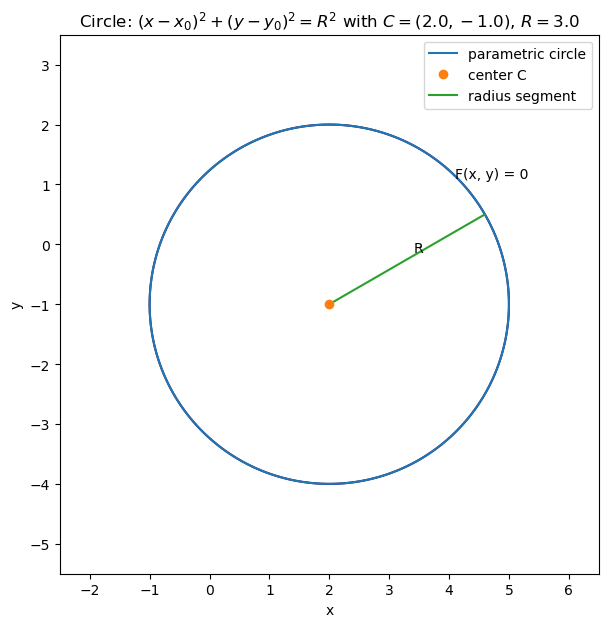

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D  # only needed if you want a legend entry for F=0

# ---- parameters ----
x0, y0 = 2.0, -1.0
R = 3.0

# ---- domain ----
pad = 1.5 * R
x_min, x_max = x0 - pad, x0 + pad
y_min, y_max = y0 - pad, y0 + pad

# ---- parametric circle ----
theta = np.linspace(0.0, 2.0*np.pi, 800, endpoint=True)
x_param = x0 + R*np.cos(theta)
y_param = y0 + R*np.sin(theta)

# ---- level set grid ----
nx = ny = 500
xs = np.linspace(x_min, x_max, nx)
ys = np.linspace(y_min, y_max, ny)
X, Y = np.meshgrid(xs, ys, indexing="xy")
F = (X - x0)**2 + (Y - y0)**2 - R**2

# ---- a convenient radius to label ----
phi = np.pi/6.0
xR = x0 + R*np.cos(phi)
yR = y0 + R*np.sin(phi)

fig, ax = plt.subplots(figsize=(7, 7))

# Draw level set first (more robust call with 1-D grid vectors)
ax.contour(xs, ys, F, levels=[0.0], zorder=1)

# Draw the parametric circle last so its color matches the legend entry you see
h_param, = ax.plot(x_param, y_param, label="parametric circle", zorder=3)

# Center & radius segment
ax.plot([x0], [y0], marker="o", linestyle="none", label="center C", zorder=4)
ax.plot([x0, xR], [y0, yR], linestyle="-", label="radius segment", zorder=3)
xm, ym = (x0 + xR)/2.0, (y0 + yR)/2.0
ax.annotate("R", xy=(xm, ym), xytext=(5, 5), textcoords="offset points")

# Option A (simplest): label the level set with an in-figure text instead of a legend handle
ax.text(x0 + 0.7*R, y0 + 0.7*R, "F(x, y) = 0")

# Option B (if you want it in the legend too): add a proxy handle
# proxy = Line2D([], [], linestyle='-', label="F(x, y) = 0")
# ax.legend(handles=[h_param, proxy, *ax.get_legend_handles_labels()[0][1:]], loc="upper right")

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(rf"Circle: $(x-x_0)^2+(y-y_0)^2=R^2$ with $C=({x0:.1f},{y0:.1f})$, $R={R:.1f}$")
ax.legend(loc="upper right")
plt.show()

# 2

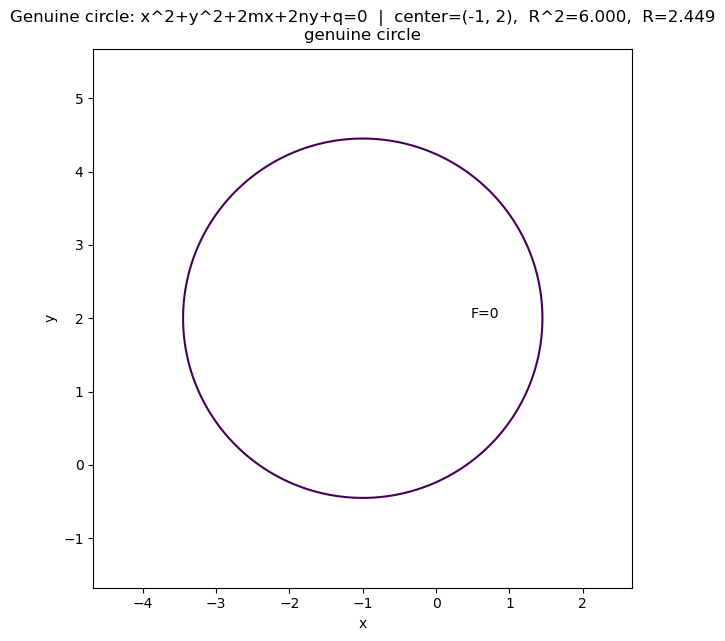

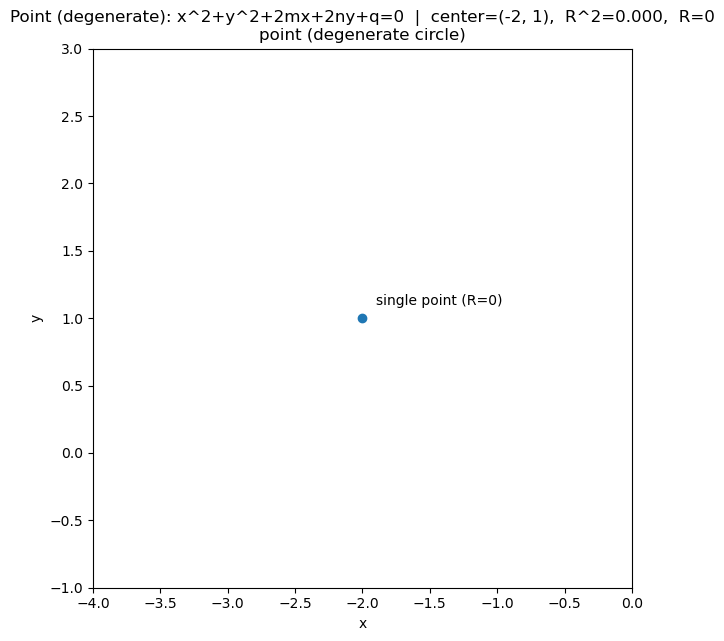

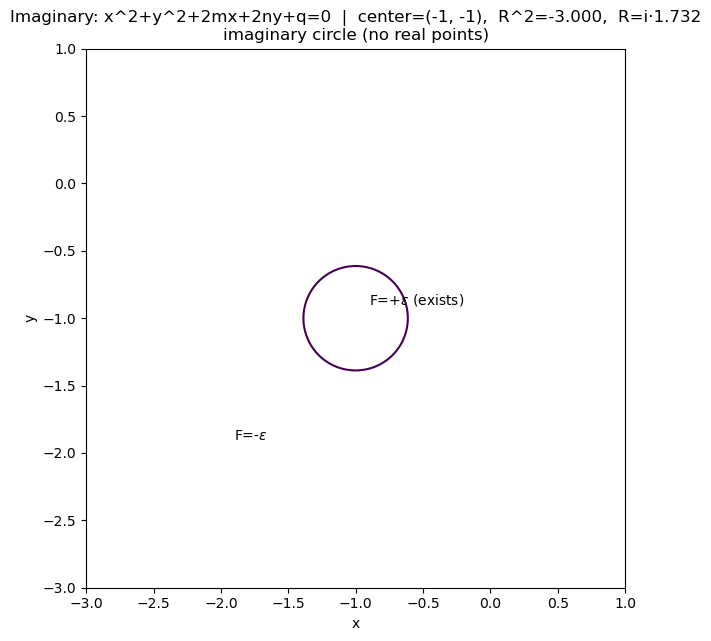

Summary (m, n, q -> x0, y0, R^2, kind):
(+1.000, -2.000, -1.000) -> x0=-1.000, y0=+2.000, R^2=+6.000  [genuine circle]
(+2.000, -1.000, +5.000) -> x0=-2.000, y0=+1.000, R^2=+0.000  [point (degenerate circle)]
(+1.000, +1.000, +5.000) -> x0=-1.000, y0=-1.000, R^2=-3.000  [imaginary circle (no real points)]


In [2]:
# Exercise 2: Complete the square and extract (x0, y0), R.
# Then generate three instances: circle (R^2>0), point (R^2=0), imaginary (R^2<0),
# and plot the level set(s) as requested.
#
# Plotting rules:
# - matplotlib only
# - one chart per figure
# - no explicit colors
#
# We optionally use SymPy to symbolically verify the completion-of-the-square identity.

import numpy as np
import matplotlib.pyplot as plt



def circle_params(m, n, q):
    """Return center (x0,y0), R^2, and a classification string."""
    x0, y0 = -m, -n
    R2 = m*m + n*n - q
    if R2 > 0:
        kind = "genuine circle"
    elif np.isclose(R2, 0.0):
        kind = "point (degenerate circle)"
    else:
        kind = "imaginary circle (no real points)"
    return (x0, y0), R2, kind

def F_grid(xs, ys, x0, y0, R2):
    """Compute F(x,y) = (x - x0)^2 + (y - y0)^2 - R^2 on a mesh grid."""
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    F = (X - x0)**2 + (Y - y0)**2 - R2
    return X, Y, F

def plot_level_set(m, n, q, title_suffix="", epsilon=None):
    """Plot the requested level set(s) for the given coefficients."""
    (x0, y0), R2, kind = circle_params(m, n, q)

    # Domain sizing
    if R2 > 0:
        R = float(np.sqrt(R2))
        pad = 1.5 * R
    else:
        # For point/imaginary, choose a modest fixed pad around the would-be center.
        pad = 2.0

    x_min, x_max = x0 - pad, x0 + pad
    y_min, y_max = y0 - pad, y0 + pad

    xs = np.linspace(x_min, x_max, 600)
    ys = np.linspace(y_min, y_max, 600)

    X, Y, F = F_grid(xs, ys, x0, y0, R2)

    fig, ax = plt.subplots(figsize=(7, 7))

    if R2 > 0:
        # Genuine circle: plot F=0 as a contour
        cs = ax.contour(xs, ys, F, levels=[0.0])
        # Optional label near the circle
        ax.text(x0 + 0.6*np.sqrt(R2), y0, "F=0")
    elif np.isclose(R2, 0.0):
        # Degenerate circle: single point at (x0, y0)
        ax.plot([x0], [y0], marker='o', linestyle='none')
        ax.text(x0 + 0.1, y0 + 0.1, "single point (R=0)")
    else:
        # Imaginary circle: no F=0. Plot "best-effort" F=±epsilon.
        if epsilon is None:
            epsilon = 1.05 * abs(R2)  # choose slightly above the threshold so +epsilon exists

        # F = +epsilon
        # Draw contour if it exists in the domain
        try:
            cs1 = ax.contour(xs, ys, F, levels=[epsilon])
            ax.text(x0 + 0.1, y0 + 0.1, r"F=+$\varepsilon$ (exists)")
        except Exception:
            pass

        # F = -epsilon (this will not exist for any positive epsilon if R2<0)
        # But try and catch "no contour levels found" gracefully.
        try:
            cs2 = ax.contour(xs, ys, F, levels=[-epsilon])
            ax.text(x0 - 0.9, y0 - 0.9, r"F=-$\varepsilon$")
        except Exception:
            ax.text(x0 - 1.2, y0 - 1.0, r"F=-$\varepsilon$ (no real level)")

    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x"); ax.set_ylabel("y")

    x0s = f"{x0:.3f}".rstrip('0').rstrip('.')
    y0s = f"{y0:.3f}".rstrip('0').rstrip('.')
    if R2 >= 0:
        Rs = f"{np.sqrt(max(R2,0.0)):.3f}".rstrip('0').rstrip('.')
    else:
        Rs = f"i·{np.sqrt(abs(R2)):.3f}".rstrip('0').rstrip('.')

    ax.set_title(
        f"{title_suffix}  |  center=({x0s}, {y0s}),  R^2={R2:.3f},  R={Rs}\n"
        f"{kind}"
    )
    plt.show()
    return (x0, y0), R2, kind

# -------------------- Three instances --------------------
instances = [
    # genuine circle: m^2 + n^2 - q > 0
    dict(m=1.0, n=-2.0, q=-1.0, label="Genuine circle: x^2+y^2+2mx+2ny+q=0"),
    # point (degenerate): m^2 + n^2 - q = 0
    dict(m=2.0, n=-1.0, q=5.0, label="Point (degenerate): x^2+y^2+2mx+2ny+q=0"),
    # imaginary: m^2 + n^2 - q < 0
    dict(m=1.0, n=1.0, q=5.0, label="Imaginary: x^2+y^2+2mx+2ny+q=0"),
]

results = []
for case in instances:
    (x0, y0), R2, kind = plot_level_set(case["m"], case["n"], case["q"], title_suffix=case["label"])
    results.append((case["m"], case["n"], case["q"], x0, y0, R2, kind))

# Display a small text summary under the last figure
print("Summary (m, n, q -> x0, y0, R^2, kind):")
for m, n, q, x0, y0, R2, kind in results:
    print(f"({m:+.3f}, {n:+.3f}, {q:+.3f}) -> x0={x0:+.3f}, y0={y0:+.3f}, R^2={R2:+.3f}  [{kind}]")

# 3

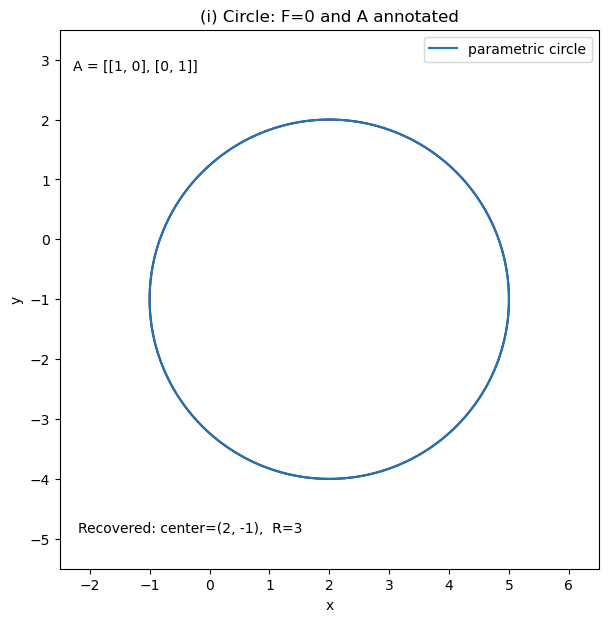

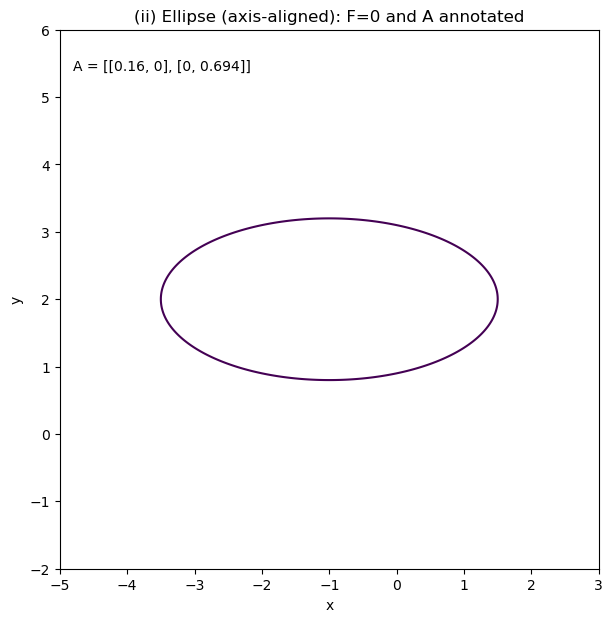

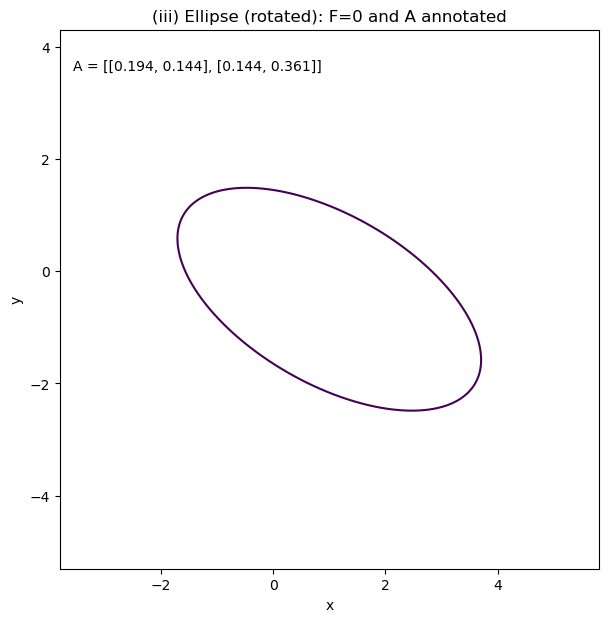

In [3]:
# Exercise 3: Recognize a circle from a general conic and visualize three cases.
# - Start with ax^2 + 2bxy + cy^2 + 2dx + 2ey + f = 0.
# - Test isotropy (circle) condition: b = 0 and a = c != 0.
# - Create three examples: (i) circle, (ii) ellipse (a != c), (iii) rotated ellipse (b != 0).
# - For each: plot level set F=0 and annotate A.
# - For the circle case: recover (x0, y0), R by completing the square and overlay the parametric circle.
#
# Plotting rules:
#   matplotlib only, one chart per figure, no explicit colors.

import numpy as np
import matplotlib.pyplot as plt

def conic_F(a, b, c, d, e, f, X, Y):
    """Evaluate F(X,Y) = a x^2 + 2 b x y + c y^2 + 2 d x + 2 e y + f on a grid."""
    return a*X*X + 2*b*X*Y + c*Y*Y + 2*d*X + 2*e*Y + f

def isotropy_test(a, b, c, tol=1e-12):
    """Return True if b=0 and a=c != 0 (within tol)."""
    return (abs(b) <= tol) and (abs(a-c) <= tol) and (abs(a) > tol)

def circle_from_conic(a, b, c, d, e, f):
    """Assuming b=0 and a=c!=0, recover (x0, y0, R)."""
    # Divide by a to reduce to x^2+y^2 + (2d/a)x + (2e/a)y + (f/a) = 0
    alpha = a
    x0 = -d / alpha
    y0 = -e / alpha
    R2 = (d*d + e*e - alpha*f) / (alpha*alpha)
    return x0, y0, R2

def plot_conic(a, b, c, d, e, f, center_hint, span_hint, title, annotate_A=True):
    """Contour F=0 on a square box centered at 'center_hint' with half-span 'span_hint'."""
    cx, cy = center_hint
    half = span_hint
    xs = np.linspace(cx-half, cx+half, 600)
    ys = np.linspace(cy-half, cy+half, 600)
    X, Y = np.meshgrid(xs, ys, indexing='xy')
    F = conic_F(a, b, c, d, e, f, X, Y)

    fig, ax = plt.subplots(figsize=(7,7))
    cs = ax.contour(xs, ys, F, levels=[0.0], zorder=1)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(cx-half, cx+half); ax.set_ylim(cy-half, cy+half)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(title)

    if annotate_A:
        A_text = f"A = [[{a:.3g}, {b:.3g}], [{b:.3g}, {c:.3g}]]"
        # Place near upper-left inside the axes
        ax.text(cx - 0.95*half, cy + 0.85*half, A_text)

    return fig, ax

# -------------------- (i) Circle example (isotropy holds) --------------------
# Choose a clean circle: center (2, -1), R = 3, and scale alpha = 1 so a=c=1, b=0.
x0_c, y0_c, R_c = 2.0, -1.0, 3.0
alpha = 1.0
a = alpha
b = 0.0
c = alpha
d = -alpha * x0_c
e = -alpha * y0_c
f = alpha * (x0_c**2 + y0_c**2 - R_c**2)

assert isotropy_test(a, b, c)

# Recover center & R from the conic and overlay parametric circle
x0_rec, y0_rec, R2_rec = circle_from_conic(a, b, c, d, e, f)
R_rec = float(np.sqrt(max(R2_rec, 0.0)))

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_c, y0_c),
                     span_hint=1.5*R_c,
                     title="(i) Circle: F=0 and A annotated")
# Parametric overlay for confirmation
theta = np.linspace(0.0, 2.0*np.pi, 800, endpoint=True)
x_param = x0_rec + R_rec * np.cos(theta)
y_param = y0_rec + R_rec * np.sin(theta)
ax.plot(x_param, y_param, zorder=2, label="parametric circle")

# Numerical labels for recovered params
ax.text(x0_c - 1.4*R_c, y0_c - 1.3*R_c,
        f"Recovered: center=({x0_rec:.3g}, {y0_rec:.3g}),  R={R_rec:.3g}")
ax.legend(loc="upper right")
plt.show()

# -------------------- (ii) Ellipse (axis-aligned, a != c, b = 0) --------------------
# Construct from center & semiaxes (rx != ry) and then convert to general conic form.
x0_e1, y0_e1 = -1.0, 2.0
rx1, ry1 = 2.5, 1.2  # unequal axes
a = 1.0 / (rx1**2)
b = 0.0
c = 1.0 / (ry1**2)
d = -x0_e1 / (rx1**2)
e = -y0_e1 / (ry1**2)
f = (x0_e1**2) / (rx1**2) + (y0_e1**2) / (ry1**2) - 1.0

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_e1, y0_e1),
                     span_hint=1.6*max(rx1, ry1),
                     title="(ii) Ellipse (axis-aligned): F=0 and A annotated")
plt.show()

# -------------------- (iii) Rotated ellipse (b != 0) --------------------
# Build from a rotated quadratic form: Q = R^T diag(1/rx^2, 1/ry^2) R.
x0_e2, y0_e2 = 1.0, -0.5
rx2, ry2 = 3.0, 1.5
theta = np.deg2rad(30.0)  # rotation angle
Rmat = np.array([[np.cos(theta), -np.sin(theta)],
                 [np.sin(theta),  np.cos(theta)]])
D = np.diag([1.0/(rx2**2), 1.0/(ry2**2)])
Q = Rmat.T @ D @ Rmat  # 2x2

# Extract a,b,c and linear terms from Q and center
a = float(Q[0,0])
b = float(Q[0,1])
c = float(Q[1,1])
cx, cy = x0_e2, y0_e2
d = float(-(Q[0,0]*cx + Q[0,1]*cy))
e = float(-(Q[1,0]*cx + Q[1,1]*cy))
f = float(cx*(Q[0,0]*cx + Q[0,1]*cy) + cy*(Q[1,0]*cx + Q[1,1]*cy) - 1.0)

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_e2, y0_e2),
                     span_hint=1.6*max(rx2, ry2),
                     title="(iii) Ellipse (rotated): F=0 and A annotated")
plt.show()

# 4

Coefficients: a=5.0, b=3.0, c=2.0
Rotation theta (rad) = 0.5535743588970452
Check: tan(2*theta) = 1.9999999999999996 ; 2b/(a-c) = 2.0
Rotated matrix A' = R^T A R =
[[6.85410197e+00 2.43306301e-16]
 [3.11387628e-16 1.45898034e-01]]
Diagonal entries (alpha, gamma) = (6.854101966249685, 0.14589803375031532)
Mixed coefficient A'12 (should be ~0) = 2.4330630117937385e-16
Isotropy (alpha == gamma)? ~ False
Coefficients: a=4.0, b=0.0, c=4.0
Rotation theta (rad) = 0.0
Check: tan(2*theta) = 0.0 ; 2b/(a-c) = ∞
Rotated matrix A' = R^T A R =
[[4. 0.]
 [0. 4.]]
Diagonal entries (alpha, gamma) = (4.0, 4.0)
Mixed coefficient A'12 (should be ~0) = 0.0
Isotropy (alpha == gamma)? ~ True


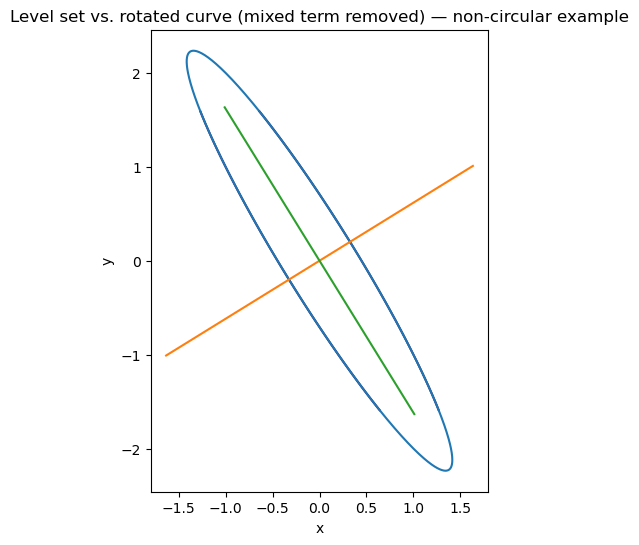

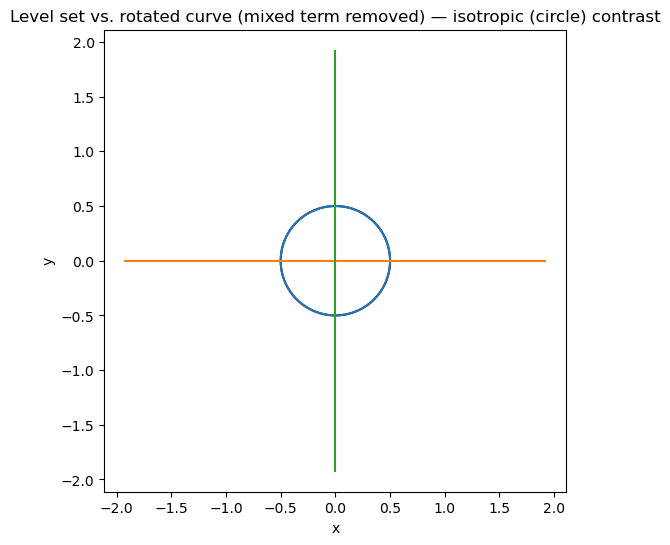

In [4]:
# Exercise 4 — Code + Run: remove mixed term by rotation and verify numerically
#
# Rules followed:
# - matplotlib only
# - one chart per figure
# - no explicit colors or styles are set
#
# The script produces:
# 1) A figure overlaying the original level set a x^2 + 2 b x y + c y^2 = 1 (contour)
#    and the rotated ellipse (α u^2 + γ v^2 = 1) mapped back to (x,y) for a non-circular case (b ≠ 0).
# 2) A second figure for an isotropic (circular) case to contrast.
# It also prints diagnostics confirming the mixed term disappears after rotation and whether α = γ.


import numpy as np
import matplotlib.pyplot as plt

def rotate_diagonalize(a, b, c):
    """Return angle theta, rotation matrix R, rotated matrix A', eigen-coeffs (alpha, gamma)."""
    theta = 0.5 * np.arctan2(2.0 * b, (a - c))  # tan(2θ) = 2b/(a - c)
    R = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])
    A = np.array([[a, b],
                  [b, c]])
    A_rot = R.T @ A @ R
    alpha = A_rot[0, 0]
    gamma = A_rot[1, 1]
    mixed = A_rot[0, 1]
    return theta, R, A_rot, alpha, gamma, mixed

def make_overlay_figure(a, b, c, title_suffix=""):
    """Overlay the original level set and the rotated parametric curve mapped back to (x,y)."""
    theta, R, A_rot, alpha, gamma, mixed = rotate_diagonalize(a, b, c)

    # Parametric curve in (u,v): alpha*u^2 + gamma*v^2 = 1 (ellipse/hyperbola branches when applicable)
    # For ellipse: alpha>0, gamma>0. We handle that common case here.
    if alpha <= 0 or gamma <= 0:
        # Fallback: choose a parametric ellipse using absolute values to visualize principal axes shape;
        # the contour for the original implicit equation still shows the correct type.
        alpha_eff = abs(alpha) if alpha != 0 else 1.0
        gamma_eff = abs(gamma) if gamma != 0 else 1.0
    else:
        alpha_eff = alpha
        gamma_eff = gamma

    t = np.linspace(0.0, 2.0*np.pi, 1000)
    u = np.cos(t) / np.sqrt(alpha_eff)
    v = np.sin(t) / np.sqrt(gamma_eff)

    # Map (u,v) back to (x,y) by the rotation [x;y] = R [u;v]
    xy = R @ np.vstack((u, v))
    x_rot, y_rot = xy[0], xy[1]

    # Grid for the original implicit contour
    # Span scaled from characteristic lengths 1/sqrt(a), 1/sqrt(c) with a bit of margin
    denom = max(1e-12, min(abs(a), abs(c)))
    span = 1.6 * max(1.0 / np.sqrt(denom), 1.0)
    grid = 501
    xs = np.linspace(-span, span, grid)
    ys = np.linspace(-span, span, grid)
    X, Y = np.meshgrid(xs, ys)
    F = a*X**2 + 2*b*X*Y + c*Y**2 - 1.0

    # Plot
    fig = plt.figure(figsize=(7, 6))
    plt.contour(X, Y, F, levels=[0.0])
    plt.plot(x_rot, y_rot)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.xlabel("x")
    plt.ylabel("y")

    # Draw principal axes (images of u- and v-axes)
    u_dir = R[:, 0]
    v_dir = R[:, 1]
    L = 1.2 * span
    plt.plot([-L*u_dir[0], L*u_dir[0]], [-L*u_dir[1], L*u_dir[1]])
    plt.plot([-L*v_dir[0], L*v_dir[0]], [-L*v_dir[1], L*v_dir[1]])

    # Title
    plt.title(f"Level set vs. rotated curve (mixed term removed){title_suffix}")

    # Diagnostics
    print("==============================================")
    print(f"Coefficients: a={a}, b={b}, c={c}")
    print(f"Rotation theta (rad) = {theta}")
    print(f"Check: tan(2*theta) = {np.tan(2*theta)} ; 2b/(a-c) = {2*b/(a-c) if a!=c else '∞'}")
    print("Rotated matrix A' = R^T A R =")
    print(A_rot)
    print(f"Diagonal entries (alpha, gamma) = ({alpha}, {gamma})")
    print(f"Mixed coefficient A'12 (should be ~0) = {mixed}")
    print(f"Isotropy (alpha == gamma)? ~ {np.isclose(alpha, gamma)}")

# ---- Case 1: non-circular (b ≠ 0) ----
a1, b1, c1 = 5.0, 3.0, 2.0
make_overlay_figure(a1, b1, c1, title_suffix=" — non-circular example")

# ---- Case 2: circular (b = 0, a = c) for contrast ----
a2, b2, c2 = 4.0, 0.0, 4.0
make_overlay_figure(a2, b2, c2, title_suffix=" — isotropic (circle) contrast")

plt.show()

=== Discriminant & distance check ===
Secant    p=0.600 r=0.366  Δ=22.630400  d=2.200000  (d ? R) -> d-R = -0.800000
Tangent   p=0.600 r=1.299  Δ=0.000000  d=3.000000  (d ? R) -> d-R = 0.000000
  Tangency check: |d - R| = 0.0
External  p=0.600 r=2.232  Δ=-29.593600  d=3.800000  (d ? R) -> d-R = 0.800000


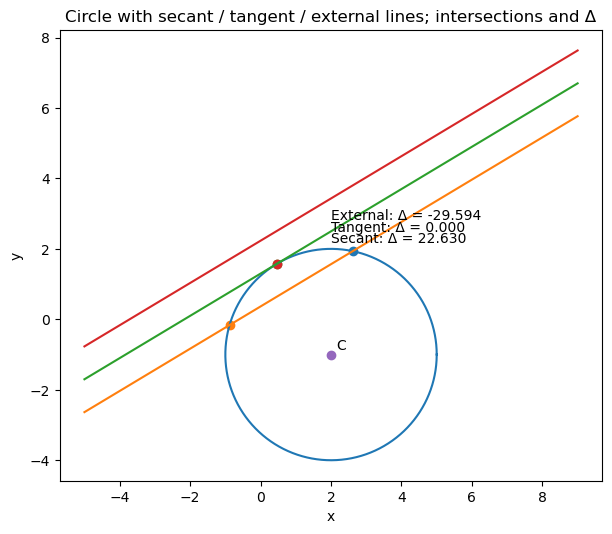

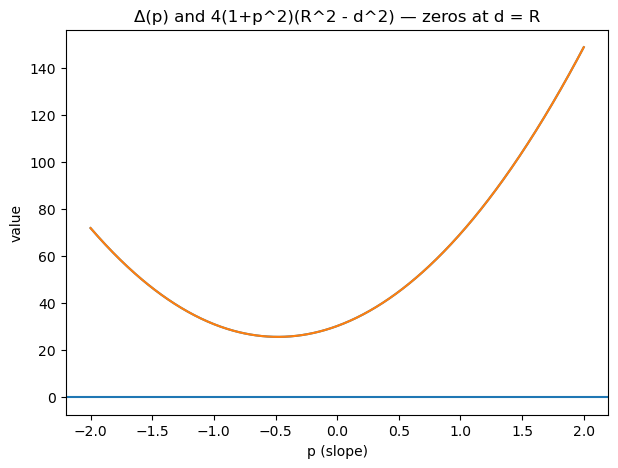

In [6]:
# Exercise 5 — Intersections with lines and tangency via discriminant
#
# Outputs:
# 1) Figure A: Circle with three representative lines (secant, tangent, external).
#    - Intersection points are marked.
#    - Δ (discriminant) values are annotated.
# 2) Figure B: Sweep over p for a fixed r, plotting Δ(p) and |R^2 - d^2|(1+p^2)*4 equivalence.
#    - Verifies Δ = 4(1+p^2)(R^2 - d^2); zeros occur exactly at d = R.
#
# Rules honored: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

# ---------------- Circle parameters ----------------
x0, y0 = 2.0, -1.0
R = 3.0

# ------------- Helper functions --------------------
def quad_coeffs_for_line(a, b, c, x0, y0, R, p, r):
    """Quadratic in x after substituting y = p x + r into circle (x-x0)^2 + (y-y0)^2 = R^2.
       Returns A,B,C for A x^2 + B x + C = 0, and discriminant Δ.
    """
    A = 1.0 + p**2
    B = -2.0*x0 + 2.0*p*(r - y0)
    C = x0**2 + (r - y0)**2 - R**2
    Δ = B**2 - 4.0*A*C
    return A, B, C, Δ

def distance_center_to_line(p, r, x0, y0):
    """Perpendicular distance from (x0,y0) to line y = p x + r."""
    return abs(p*x0 - y0 + r) / np.sqrt(1.0 + p**2)

def circle_xy(theta, x0, y0, R):
    return x0 + R*np.cos(theta), y0 + R*np.sin(theta)

# ------------------ Construct lines -----------------
# We'll use a single slope p and create three lines via r chosen around tangency.
p = 0.6
root = np.sqrt(1.0 + p**2)

# Tangent lines satisfy |p x0 - y0 + r| = R * sqrt(1 + p^2).
# Choose one sign (s = +1) to pick a specific tangent.
s = 1.0
r_tan = -p*x0 + y0 + s * R * root

# Create secant/external by shifting r above/below tangency by an amount that changes distance.
delta = 0.8 * root  # distance shift of 0.8 in the numerator -> ~0.8 in distance due to division by root
r_sec = r_tan - s * delta   # distance smaller than R => secant
r_ext = r_tan + s * delta   # distance larger than R => external

# Compute discriminants and intersections
cases = [("Secant", p, r_sec),
         ("Tangent", p, r_tan),
         ("External", p, r_ext)]

results = []
for name, pp, rr in cases:
    A, B, C, Δ = quad_coeffs_for_line(1, 0, 1, x0, y0, R, pp, rr)
    d = distance_center_to_line(pp, rr, x0, y0)
    # Intersections (only real if Δ >= 0)
    pts = []
    if Δ >= 0:
        xs = (-B + np.array([+np.sqrt(Δ), -np.sqrt(Δ)])) / (2.0*A)
        for xi in xs:
            yi = pp*xi + rr
            pts.append((xi, yi))
    results.append((name, pp, rr, Δ, d, pts))

# ------------------ Figure A ------------------------
# Plot circle
theta = np.linspace(0.0, 2.0*np.pi, 800)
xc, yc = circle_xy(theta, x0, y0, R)

fig1 = plt.figure(figsize=(7, 6))
plt.plot(xc, yc)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel("x")
plt.ylabel("y")
plt.title("Circle with secant / tangent / external lines; intersections and Δ")

# Axis span to include all lines
span_x = R + abs(x0) + 2.0
xs = np.linspace(x0 - span_x, x0 + span_x, 400)

# Draw and annotate each line
y_offsets = np.linspace(0.6, -0.6, len(results))
for (name, pp, rr, Δ, d, pts), yoff in zip(results, y_offsets):
    ys = pp*xs + rr
    plt.plot(xs, ys)
    # mark intersections
    for (xi, yi) in pts:
        plt.scatter([xi], [yi])
    # annotate Δ near the center projection onto the line
    # pick a reference x mid and place text slightly offset
    xm = np.clip(x0, xs.min()+0.5, xs.max()-0.5)
    ym = pp*xm + rr
    plt.text(xm, ym + yoff, f"{name}: Δ = {Δ:.3f}")

# Mark center
plt.scatter([x0], [y0])
plt.text(x0 + 0.15, y0 + 0.15, "C")

# Print numeric table
print("=== Discriminant & distance check ===")
for name, pp, rr, Δ, d, pts in results:
    print(f"{name:8s}  p={pp:.3f} r={rr:.3f}  Δ={Δ:.6f}  d={d:.6f}  (d ? R) -> d-R = {d-R:.6f}")
    if name == "Tangent":
        print("  Tangency check: |d - R| =", abs(d - R))

# ------------------ Figure B: Δ vs p sweep (fixed r) ------------------
# Fix r and sweep p to verify zeros when d=R
r_fixed = -p*x0 + y0  # line through the center in slope-intercept form (secant when p != 0)
p_vals = np.linspace(-2.0, 2.0, 600)
A = 1.0 + p_vals**2
B = -2.0*x0 + 2.0*p_vals*(r_fixed - y0)
C = x0**2 + (r_fixed - y0)**2 - R**2
Delta_vals = B**2 - 4.0*A*C

# Compute the expression 4(1+p^2)(R^2 - d^2) which should equal Δ
d_vals = np.abs(p_vals*x0 - y0 + r_fixed) / np.sqrt(1.0 + p_vals**2)
equiv_vals = 4.0*(1.0 + p_vals**2)*(R**2 - d_vals**2)

fig2 = plt.figure(figsize=(7, 5))
plt.plot(p_vals, Delta_vals)
plt.plot(p_vals, equiv_vals)
plt.xlabel("p (slope)")
plt.ylabel("value")
plt.title("Δ(p) and 4(1+p^2)(R^2 - d^2) — zeros at d = R")
plt.axhline(0.0)

plt.show()

# 6

=== Case A: Non-collinear points ===
Points:
 [[ 0.  1.]
 [ 3.  2.]
 [ 2. -2.]]
Linear system A u = b with u=(m,n,q):
A =
 [[ 0.  2.  1.]
 [ 6.  4.  1.]
 [ 4. -4.  1.]]
b =
 [ -1. -13.  -8.]
Solution (m, n, q) = (-1.954545, -0.136364, -0.727273)
Recovered center (x0, y0) = (1.954545, 0.136364)
Recovered radius R = 2.136847
Condition number κ(A) = 7.441e+00

=== Case B: Nearly collinear points ===
Points:
 [[0.    1.   ]
 [2.    1.401]
 [4.    1.802]]
A =
 [[0.    2.    1.   ]
 [4.    2.802 1.   ]
 [8.    3.604 1.   ]]
b =
 [ -1.        -5.962801 -19.247204]
Solution (m, n, q) = (1878542828774567.500000, -9369290916581396.000000, 18738581833162792.000000)
Recovered center (x0, y0) = (-1878542828774567.500000, 9369290916581396.000000)
Recovered radius R = 9555759281139044.000000
Condition number κ(A) = 3.364e+16  (large ⇒ ill-conditioned)


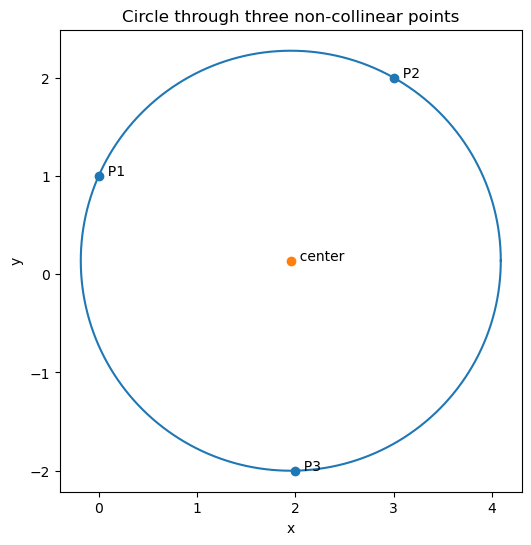

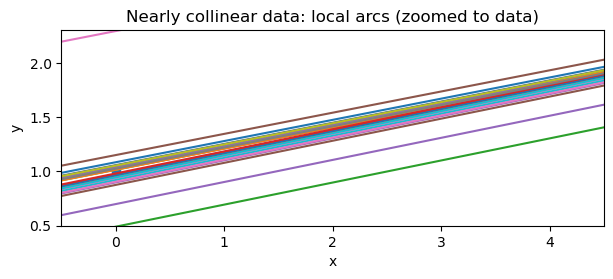

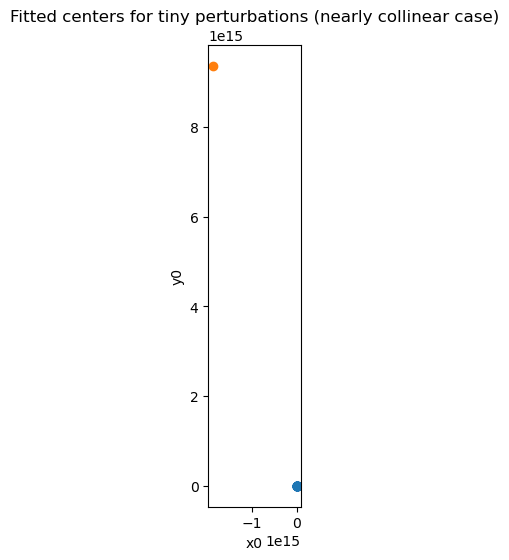

In [8]:

# Exercise 6 — Updated, complete code
#
# Improvements vs prior:
# - Zooms the "nearly collinear" plot to the neighborhood of the data (so you see local arcs).
# - Adds a separate figure for the cloud of fitted centers (often far away).
# - Prints robust diagnostics (system matrices, solutions, condition numbers).
#
# Rules: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

def fit_circle_three_points(P):
    """Given three points P = [(x1,y1), (x2,y2), (x3,y3)],
    solve for (m, n, q) in x^2 + y^2 + 2 m x + 2 n y + q = 0.
    Return (m, n, q), center (x0, y0), radius R, system matrix A, RHS b.
    """
    P = np.asarray(P, dtype=float).reshape(3, 2)
    x = P[:, 0]
    y = P[:, 1]
    A = np.column_stack((2.0*x, 2.0*y, np.ones(3)))
    b = -(x**2 + y**2)
    sol = np.linalg.solve(A, b)  # raises if exactly collinear
    m, n, q = sol
    x0, y0 = -m, -n
    R = np.sqrt(max(0.0, x0**2 + y0**2 - q))
    return (m, n, q), (x0, y0), R, A, b

def circle_param(center, R, n=800):
    t = np.linspace(0.0, 2.0*np.pi, n)
    return center[0] + R*np.cos(t), center[1] + R*np.sin(t)

# -------------------- Case A: well-conditioned (non-collinear) --------------------
P_good = np.array([[0.0, 1.0],
                   [3.0, 2.0],
                   [2.0, -2.0]])

(mA, nA, qA), C_good, R_good, A_good, b_good = fit_circle_three_points(P_good)
cond_good = np.linalg.cond(A_good)

# Figure A
xg, yg = circle_param(C_good, R_good)
fig1 = plt.figure(figsize=(7, 6))
plt.plot(xg, yg)
plt.scatter(P_good[:, 0], P_good[:, 1])
plt.scatter([C_good[0]], [C_good[1]])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Circle through three non-collinear points")
plt.text(C_good[0], C_good[1], "  center")
for i, (xi, yi) in enumerate(P_good):
    plt.text(xi, yi, f"  P{i+1}")
plt.gca().set_aspect('equal', adjustable='box')

print("=== Case A: Non-collinear points ===")
print("Points:\n", P_good)
print("Linear system A u = b with u=(m,n,q):")
print("A =\n", A_good)
print("b =\n", b_good)
print(f"Solution (m, n, q) = ({mA:.6f}, {nA:.6f}, {qA:.6f})")
print(f"Recovered center (x0, y0) = ({C_good[0]:.6f}, {C_good[1]:.6f})")
print(f"Recovered radius R = {R_good:.6f}")
print(f"Condition number κ(A) = {cond_good:.3e}")

# -------------------- Case B: nearly collinear --------------------
# Construct three points almost on a line y = s x + t with tiny offsets
s, t = 0.2, 1.0
eps = 1.0e-3  # small non-collinearity
x_vals = np.array([0.0, 2.0, 4.0])
y_vals = s*x_vals + t + np.array([0.0, eps, 2.0*eps])
P_near = np.column_stack((x_vals, y_vals))

(mB, nB, qB), C_near, R_near, A_near, b_near = fit_circle_three_points(P_near)
cond_near = np.linalg.cond(A_near)

print("\n=== Case B: Nearly collinear points ===")
print("Points:\n", P_near)
print("A =\n", A_near)
print("b =\n", b_near)
print(f"Solution (m, n, q) = ({mB:.6f}, {nB:.6f}, {qB:.6f})")
print(f"Recovered center (x0, y0) = ({C_near[0]:.6f}, {C_near[1]:.6f})")
print(f"Recovered radius R = {R_near:.6f}")
print(f"Condition number κ(A) = {cond_near:.3e}  (large ⇒ ill-conditioned)")

# Multiple tiny perturbations to visualize instability
rng = np.random.default_rng(7)
n_trials = 30
pert_sigma = 2.0e-3  # very small noise
centers = []
circles = []

for _ in range(n_trials):
    noise = pert_sigma * rng.standard_normal(P_near.shape)
    Pp = P_near + noise
    try:
        (_, _, _), C_p, R_p, _, _ = fit_circle_three_points(Pp)
        centers.append(C_p)
        circles.append((C_p, R_p))
    except np.linalg.LinAlgError:
        continue

centers = np.array(centers) if centers else np.zeros((0, 2))

# Figure B: overlay many fitted circles — ZOOMED to the data neighborhood
fig2 = plt.figure(figsize=(7, 6))
# base circle arc (full circle computed, but we will zoom)
xb, yb = circle_param(C_near, R_near)
plt.plot(xb, yb)
for C_p, R_p in circles:
    xp, yp = circle_param(C_p, R_p, n=400)
    plt.plot(xp, yp)
# points
plt.scatter(P_near[:, 0], P_near[:, 1])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Nearly collinear data: local arcs (zoomed to data)")
plt.gca().set_aspect('equal', adjustable='box')
# ZOOM: frame around the three data points
pad = 0.5
xmin, xmax = P_near[:,0].min()-pad, P_near[:,0].max()+pad
ymin, ymax = P_near[:,1].min()-pad, P_near[:,1].max()+pad
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Figure C: centers-only, separate scale to show how far they wander
fig3 = plt.figure(figsize=(7, 6))
if len(centers) > 0:
    plt.scatter(centers[:, 0], centers[:, 1])
# mark the unperturbed center as well
plt.scatter([C_near[0]], [C_near[1]])
plt.xlabel("x0")
plt.ylabel("y0")
plt.title("Fitted centers for tiny perturbations (nearly collinear case)")
plt.gca().set_aspect('equal', adjustable='box')

plt.show()

# 7

=== Linearized algebraic circle fit ===
Estimated parameters (m, n, q) = (-2.009050, 0.987021, -3.989485)
True center (x0, y0) = (2.000000, -1.000000),  True R = 3.000000
Fitted center (x0, y0) = (2.009050, -0.987021),  Fitted R = 2.999996
Coordinate noise sigma = 0.0600
RMS radial residual (to fitted circle) = 0.0498


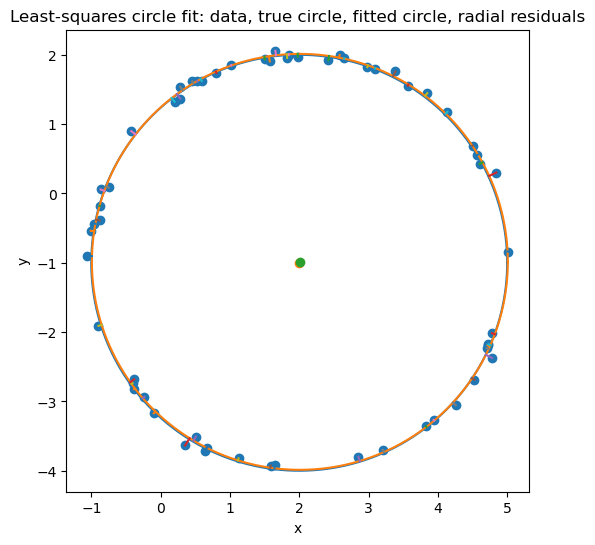

In [9]:
# Exercise 7 — Least‑squares circle fit (overdetermined case)
#
# Outputs:
# 1) One figure: noisy data cloud, true circle, fitted circle, and radial residual segments.
# 2) Printed diagnostics: estimated (m, n, q), extracted center/radius, RMS radial residual,
#    and comparison to the injected noise level.
#
# Rules: matplotlib only, one chart per figure, no explicit colors or styles.

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(12345)

# ---- Ground-truth circle ----
x0_true, y0_true = 2.0, -1.0
R_true = 3.0

# ---- Sample noisy points near the true circle ----
N = 60
theta = rng.uniform(0.0, 2.0*np.pi, size=N)

# Base points on the exact circle
Xc = x0_true + R_true * np.cos(theta)
Yc = y0_true + R_true * np.sin(theta)

# Add isotropic Gaussian noise in the plane
sigma = 0.06  # coordinate noise std dev
X = Xc + rng.normal(0.0, sigma, size=N)
Y = Yc + rng.normal(0.0, sigma, size=N)
pts = np.column_stack((X, Y))

# ---- Linearized algebraic fit: A u = b in least squares ----
# Model: x^2 + y^2 + 2 m x + 2 n y + q = 0
A = np.column_stack((2.0*X, 2.0*Y, np.ones(N)))
b = -(X**2 + Y**2)
u, *_ = np.linalg.lstsq(A, b, rcond=None)
m_hat, n_hat, q_hat = u

# Extract center and radius
x0_hat, y0_hat = -m_hat, -n_hat
R_hat = np.sqrt(max(0.0, x0_hat**2 + y0_hat**2 - q_hat))

# ---- Radial residuals (signed) to fitted circle ----
# sign convention: positive if point lies outside fitted circle
dists = np.sqrt((X - x0_hat)**2 + (Y - y0_hat)**2)
residuals = dists - R_hat
rms_resid = np.sqrt(np.mean(residuals**2))

# Points on fitted circumference along the radial direction (for line segments)
# Avoid division by zero when a point coincides with the center (overwhelmingly unlikely here).
vecs = np.column_stack((X - x0_hat, Y - y0_hat))
norms = np.linalg.norm(vecs, axis=1)
# Replace zeros with 1 to avoid division (segment would be degenerate anyway)
norms = np.where(norms == 0.0, 1.0, norms)
uvecs = vecs / norms[:, None]
proj = np.column_stack((x0_hat, y0_hat)) + R_hat * uvecs

# ---- Plot ----
# True and fitted circles (parametric)
t = np.linspace(0.0, 2.0*np.pi, 800)
xt = x0_true + R_true * np.cos(t)
yt = y0_true + R_true * np.sin(t)
xf = x0_hat + R_hat * np.cos(t)
yf = y0_hat + R_hat * np.sin(t)

fig = plt.figure(figsize=(7, 6))
plt.plot(xt, yt)            # true circle
plt.plot(xf, yf)            # fitted circle
plt.scatter(X, Y)           # noisy data
# residual segments
for (xi, yi), (xpi, ypi) in zip(pts, proj):
    plt.plot([xi, xpi], [yi, ypi])
# mark centers
plt.scatter([x0_true], [y0_true])
plt.scatter([x0_hat], [y0_hat])
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel("x")
plt.ylabel("y")
plt.title("Least-squares circle fit: data, true circle, fitted circle, radial residuals")

# ---- Diagnostics ----
print("=== Linearized algebraic circle fit ===")
print(f"Estimated parameters (m, n, q) = ({m_hat:.6f}, {n_hat:.6f}, {q_hat:.6f})")
print(f"True center (x0, y0) = ({x0_true:.6f}, {y0_true:.6f}),  True R = {R_true:.6f}")
print(f"Fitted center (x0, y0) = ({x0_hat:.6f}, {y0_hat:.6f}),  Fitted R = {R_hat:.6f}")
print(f"Coordinate noise sigma = {sigma:.4f}")
print(f"RMS radial residual (to fitted circle) = {rms_resid:.4f}")

plt.show()


# 8

=== Translational invariance: diagnostics ===
Max |F_orig(x,y)| over sampled points: 3.553e-15
Max |F_translated(xt,yt)| over translated points: 5.329e-15


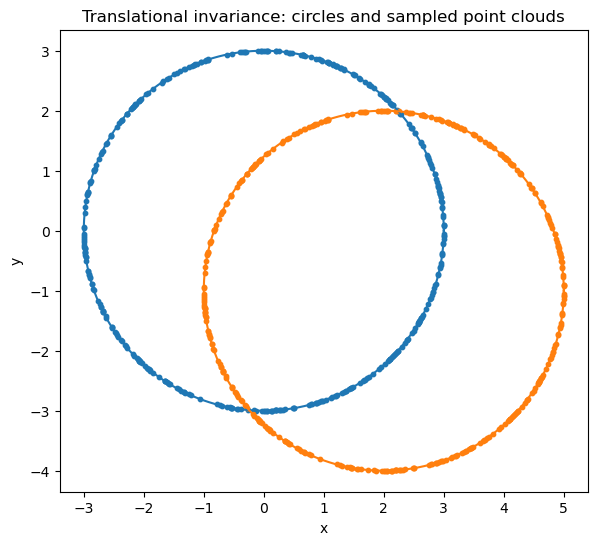

In [10]:
# Exercise 8 — Translational invariance check
#
# One figure: original circle & cloud; translated circle & cloud (overlaid).
# Printed diagnostics: max |F| for both clouds under their respective implicit equations.
#
# Rules: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

# Parameters
R = 3.0
x0, y0 = 2.0, -1.0  # translation

# Sample points on the original circle
rng = np.random.default_rng(7)
N = 400
theta = rng.uniform(0.0, 2.0*np.pi, size=N)
x = R * np.cos(theta)
y = R * np.sin(theta)

# Translate the samples
xt = x + x0
yt = y + y0

# Implicit functions
F_orig = x**2 + y**2 - R**2
F_translated = (xt - x0)**2 + (yt - y0)**2 - R**2

# Diagnostics: numerical tolerance checks
max_abs_F_orig = np.max(np.abs(F_orig))
max_abs_F_trans = np.max(np.abs(F_translated))

print("=== Translational invariance: diagnostics ===")
print(f"Max |F_orig(x,y)| over sampled points: {max_abs_F_orig:.3e}")
print(f"Max |F_translated(xt,yt)| over translated points: {max_abs_F_trans:.3e}")

# Curves for drawing the two implicit circles
t = np.linspace(0.0, 2.0*np.pi, 800)
xc, yc = R*np.cos(t), R*np.sin(t)                 # original circle
xct, yct = x0 + R*np.cos(t), y0 + R*np.sin(t)     # translated circle

# Plot
fig = plt.figure(figsize=(7, 6))
plt.plot(xc, yc)          # original circle curve
plt.plot(xct, yct)        # translated circle curve
plt.scatter(x, y, s=10)   # original cloud
plt.scatter(xt, yt, s=10) # translated cloud
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel("x")
plt.ylabel("y")
plt.title("Translational invariance: circles and sampled point clouds")

plt.show()


# 9

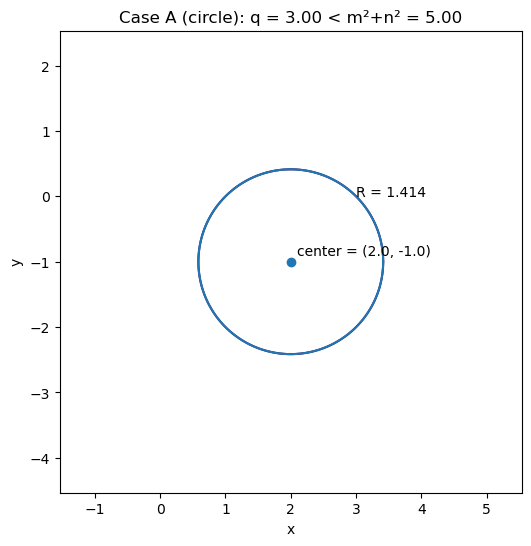

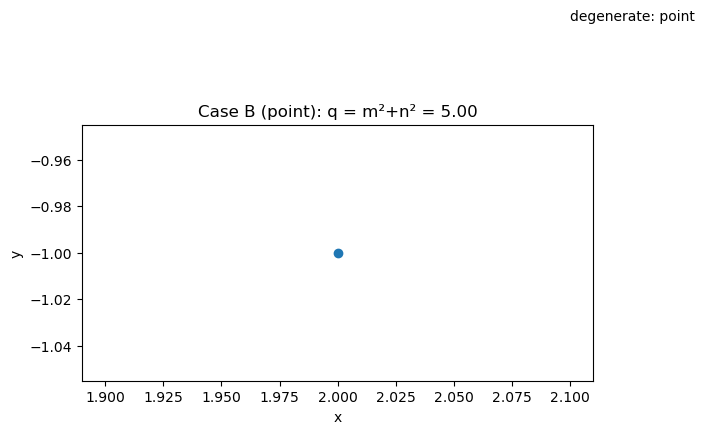

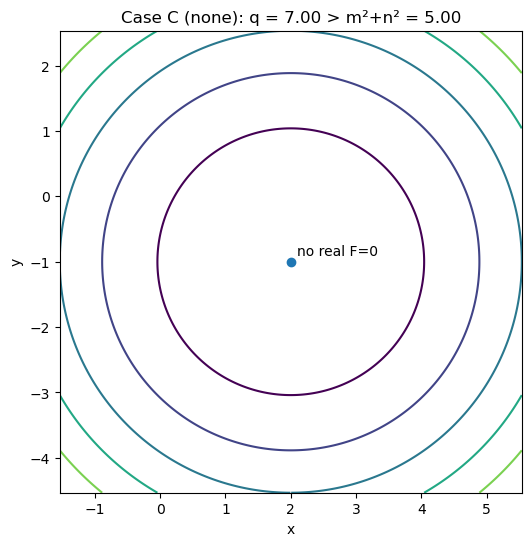

In [11]:
# Exercise 9 — Level-set portrait of F(x,y) = x^2 + y^2 + 2 m x + 2 n y + q
#
# We produce three separate figures (one per case) instead of subplots,
# to follow the "one chart per figure" rule.
#
# Case A: q < m^2 + n^2  → real circle, radius R = sqrt(m^2 + n^2 - q)
# Case B: q = m^2 + n^2  → single point (degenerate circle)
# Case C: q > m^2 + n^2  → no real points
#
# On the circle case we annotate R; on the degenerate case we mark the point.
#
# Rules: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

# Fixed (m, n); center is (-m, -n)
m, n = -2.0, 1.0
center = (-m, -n)
threshold = m*m + n*n  # m^2 + n^2 = 5.0

# Choose q values around the threshold
q_vals = {
    "A (circle)": threshold - 2.0,   # q = 3.0  -> circle
    "B (point)":  threshold,         # q = 5.0  -> single point
    "C (none)":   threshold + 2.0    # q = 7.0  -> no real locus
}

def make_grid(center, span, nx=600):
    x0, y0 = center
    xs = np.linspace(x0 - span, x0 + span, nx)
    ys = np.linspace(y0 - span, y0 + span, nx)
    X, Y = np.meshgrid(xs, ys)
    return X, Y

def F(x, y, m, n, q):
    return x**2 + y**2 + 2*m*x + 2*n*y + q

# Determine a reasonable span from the circle case radius (or a default)
R_circle = np.sqrt(max(0.0, threshold - (threshold - 2.0)))  # = sqrt(2)
span_default = max(3.0, 2.5 * R_circle)

# --------- Figure A: Circle (q < m^2 + n^2) ---------
qA = q_vals["A (circle)"]
RA = np.sqrt(m*m + n*n - qA)
X, Y = make_grid(center, span_default)
FA = F(X, Y, m, n, qA)

fig1 = plt.figure(figsize=(6.6, 6))
# Draw the zero level set (circle)
plt.contour(X, Y, FA, levels=[0.0])
# Also draw the parametric circle for smoothness (optional redundancy)
t = np.linspace(0, 2*np.pi, 800)
xc = center[0] + RA*np.cos(t)
yc = center[1] + RA*np.sin(t)
plt.plot(xc, yc)

# Mark center and annotate R
plt.scatter([center[0]], [center[1]])
plt.text(center[0] + 0.1, center[1] + 0.1, f"center = ({center[0]:.1f}, {center[1]:.1f})")
plt.text(center[0] + RA/np.sqrt(2), center[1] + RA/np.sqrt(2), f"R = {RA:.3f}")

plt.gca().set_aspect('equal', adjustable='box')
plt.title(f"Case A (circle): q = {qA:.2f} < m²+n² = {threshold:.2f}")
plt.xlabel("x"); plt.ylabel("y")

# --------- Figure B: Point (q = m^2 + n^2) ---------
qB = q_vals["B (point)"]
RB = 0.0
X, Y = make_grid(center, span_default)
FB = F(X, Y, m, n, qB)

fig2 = plt.figure(figsize=(6.6, 6))
# The contour can be numerically tricky at exactly zero radius; mark the point explicitly.
plt.scatter([center[0]], [center[1]])
plt.text(center[0] + 0.1, center[1] + 0.1, "degenerate: point")
plt.gca().set_aspect('equal', adjustable='box')
plt.title(f"Case B (point): q = m²+n² = {threshold:.2f}")
plt.xlabel("x"); plt.ylabel("y")

# --------- Figure C: None (q > m^2 + n^2) ---------
qC = q_vals["C (none)"]
X, Y = make_grid(center, span_default)
FC = F(X, Y, m, n, qC)

fig3 = plt.figure(figsize=(6.6, 6))
# No zero level set exists; we show a few positive contours to emphasize emptiness of F=0
levels = np.linspace(np.min(FC), np.max(FC), 7)[1:]
plt.contour(X, Y, FC, levels=levels)
plt.scatter([center[0]], [center[1]])
plt.text(center[0] + 0.1, center[1] + 0.1, "no real F=0")
plt.gca().set_aspect('equal', adjustable='box')
plt.title(f"Case C (none): q = {qC:.2f} > m²+n² = {threshold:.2f}")
plt.xlabel("x"); plt.ylabel("y")

plt.show()


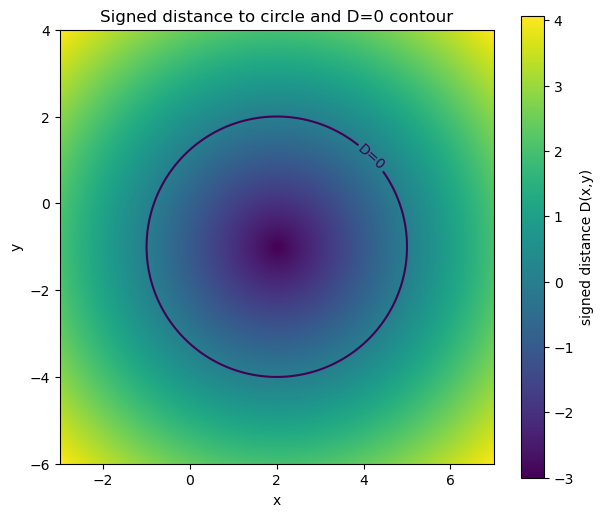

In [12]:
# Retry with explicit mappable for colorbar to avoid matplotlib picking the contour as the mappable.

import numpy as np
import matplotlib.pyplot as plt

# Parameters
x0, y0 = 2.0, -1.0
R = 3.0

span = 5.0
n = 501
xs = np.linspace(x0 - span, x0 + span, n)
ys = np.linspace(y0 - span, y0 + span, n)
X, Y = np.meshgrid(xs, ys)
D = np.sqrt((X - x0)**2 + (Y - y0)**2) - R

fig = plt.figure(figsize=(7, 6))
extent = [xs.min(), xs.max(), ys.min(), ys.max()]
im = plt.imshow(D, extent=extent, origin="lower", aspect="equal")
CS = plt.contour(X, Y, D, levels=[0.0])
plt.clabel(CS, inline=1, fmt={0.0: "D=0"})
plt.colorbar(im, label="signed distance D(x,y)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Signed distance to circle and D=0 contour")

plt.show()


=== Algebra–geometry round‑trip ===
True   (x0, y0, R) = (2.972289, -0.471961, 3.067870)
Params (m, n, q)   = (-2.972289, 0.471961, -0.354577)
Recovered           = (2.972289, -0.471961, 3.067870)
Abs errors:  |Δx0|=0.000e+00, |Δy0|=0.000e+00, |ΔR|=0.000e+00


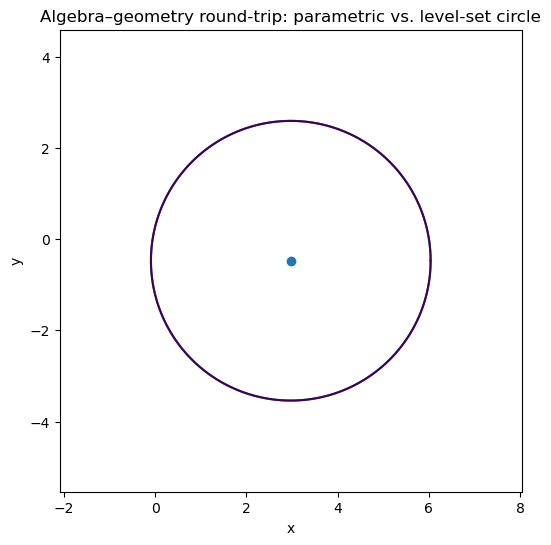

In [13]:
# Exercise 11 — Algebra–geometry round‑trip
#
# Steps:
# 1) Sample random (x0, y0, R).
# 2) Map to algebraic (m, n, q) for F(x,y)=x^2+y^2+2mx+2ny+q=0.
# 3) Recover (x0, y0, R) from (m, n, q) via completing the square.
# 4) Plot: parametric circle and level set F=0 overlaid; print diagnostics.
#
# Rules: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---- 1) Random center & radius ----
x0_true = rng.uniform(-2.0, 3.0)
y0_true = rng.uniform(-2.0, 2.0)
R_true  = rng.uniform(1.0, 3.5)

# ---- 2) Algebraic parameters ----
m = -x0_true
n = -y0_true
q = x0_true**2 + y0_true**2 - R_true**2

# ---- 3) Recover by "completing the square" formulas ----
x0_hat = -m
y0_hat = -n
R_hat = np.sqrt(max(0.0, x0_hat**2 + y0_hat**2 - q))

# ---- Diagnostics ----
print("=== Algebra–geometry round‑trip ===")
print(f"True   (x0, y0, R) = ({x0_true:.6f}, {y0_true:.6f}, {R_true:.6f})")
print(f"Params (m, n, q)   = ({m:.6f}, {n:.6f}, {q:.6f})")
print(f"Recovered           = ({x0_hat:.6f}, {y0_hat:.6f}, {R_hat:.6f})")
print("Abs errors: ",
      f"|Δx0|={abs(x0_hat-x0_true):.3e}, |Δy0|={abs(y0_hat-y0_true):.3e}, |ΔR|={abs(R_hat-R_true):.3e}")

# ---- 4) Plot overlay ----
# Parametric circle from recovered params
t = np.linspace(0.0, 2.0*np.pi, 800)
xp = x0_hat + R_hat*np.cos(t)
yp = y0_hat + R_hat*np.sin(t)

# Level-set grid for F=0 contour
span = R_hat + 2.0
xs = np.linspace(x0_hat - span, x0_hat + span, 600)
ys = np.linspace(y0_hat - span, y0_hat + span, 600)
X, Y = np.meshgrid(xs, ys)
F = X**2 + Y**2 + 2*m*X + 2*n*Y + q

fig = plt.figure(figsize=(7, 6))
plt.plot(xp, yp)                  # parametric
plt.contour(X, Y, F, levels=[0])  # implicit
plt.scatter([x0_hat], [y0_hat])   # center
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel("x"); plt.ylabel("y")
plt.title("Algebra–geometry round‑trip: parametric vs. level‑set circle")

plt.show()


# 12

=== Sensitivity (first-order) at the true parameters ===
R0 = 3.000000
∂R/∂m = -0.666667,  ∂R/∂n = 0.333333,  ∂R/∂q = -0.166667
Interpretation: influence ~ |partial| × |perturbation|.
For centers far from the origin, |m| and |n| grow, so errors in m,n dominate;
near the origin, dq tends to dominate because |∂R/∂q| = 1/(2R) stays finite.


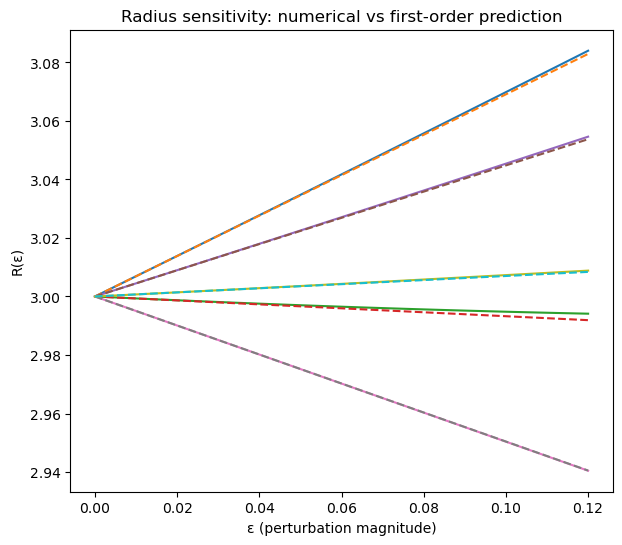


=== Small-ε check (ε = 1e-3, one random direction) ===
Numerical R(ε)   = 3.00069099
Linear approx     = 3.00069091
Abs difference    = 7.782e-08


In [14]:
# Exercise 12 — Sensitivity of the radius to small coefficient errors
#
# Part 1 (derivation, summarized in comments):
#   R(m,n,q) = sqrt(m^2 + n^2 - q)
#   dR = (1/(2R)) * (2 m dm + 2 n dn - dq) = (m dm + n dn)/R - (dq)/(2R)
#   ⇒ First-order prediction for a perturbation (dm, dn, dq):  R' ≈ R + dR
#
# Part 2 (numerics):
#   - Fix a true circle (x0,y0,R_true), compute (m,n,q).
#   - Draw several random *directions* in (dm,dn,dq) and scale them by ε.
#   - Compare the numerical R(ε) with the first-order prediction for a sweep of ε.
#   - Report partial derivatives to comment on which coefficient is most influential.
#
# Rules: matplotlib only, one chart per figure, no explicit colors/styles.

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ----- True circle and algebraic parameters -----
x0, y0, R_true = 2.0, -1.0, 3.0
m0, n0, q0 = -x0, -y0, x0**2 + y0**2 - R_true**2

# Base radius from (m0,n0,q0) — should equal R_true
R0 = np.sqrt(m0**2 + n0**2 - q0)

# First-order sensitivity coefficients (partials of R at (m0,n0,q0))
dR_dm = m0 / R0
dR_dn = n0 / R0
dR_dq = -1.0 / (2.0 * R0)

print("=== Sensitivity (first-order) at the true parameters ===")
print(f"R0 = {R0:.6f}")
print(f"∂R/∂m = {dR_dm:.6f},  ∂R/∂n = {dR_dn:.6f},  ∂R/∂q = {dR_dq:.6f}")
print("Interpretation: influence ~ |partial| × |perturbation|.")
print("For centers far from the origin, |m| and |n| grow, so errors in m,n dominate;")
print("near the origin, dq tends to dominate because |∂R/∂q| = 1/(2R) stays finite.")

# ----- Build a few random perturbation directions in (dm,dn,dq) -----
num_dirs = 5
dirs = rng.normal(size=(num_dirs, 3))
dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)  # unit directions

# Epsilon sweep (perturbation size)
eps = np.linspace(0.0, 0.12, 80)  # up to ~0.12 in coefficient units

# Prepare figure
fig = plt.figure(figsize=(7, 6))
plt.xlabel("ε (perturbation magnitude)")
plt.ylabel("R(ε)")
plt.title("Radius sensitivity: numerical vs first-order prediction")

for v in dirs:
    dm_dir, dn_dir, dq_dir = v
    R_num = []
    R_lin = []
    for e in eps:
        dm, dn, dq = e*dm_dir, e*dn_dir, e*dq_dir
        # Numerical perturbed radius
        R_num.append(np.sqrt((m0+dm)**2 + (n0+dn)**2 - (q0+dq)))
        # First-order prediction: R + dR
        dR = (m0*dm + n0*dn)/R0 - dq/(2.0*R0)
        R_lin.append(R0 + dR)
    R_num = np.array(R_num)
    R_lin = np.array(R_lin)
    # Plot both; the proximity of the two curves for small ε validates the linearization
    plt.plot(eps, R_num)
    plt.plot(eps, R_lin, linestyle="--")

plt.show()

# Also, demonstrate single-direction error scaling in a small-epsilon regime
e_small = 1e-3
v = dirs[0]
dm, dn, dq = e_small*v
R_num_small = np.sqrt((m0+dm)**2 + (n0+dn)**2 - (q0+dq))
dR_small = (m0*dm + n0*dn)/R0 - dq/(2.0*R0)
R_lin_small = R0 + dR_small
print("\n=== Small-ε check (ε = 1e-3, one random direction) ===")
print(f"Numerical R(ε)   = {R_num_small:.8f}")
print(f"Linear approx     = {R_lin_small:.8f}")
print(f"Abs difference    = {abs(R_num_small - R_lin_small):.3e}")
